In [2]:
import pandas as pd

In [3]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "fake_job_postings.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "shivamb/real-or-fake-fake-jobposting-prediction",
  file_path,
)
print("First 5 records:", df.head())
df.head()

c:\Users\itsaa\OneDrive\Desktop\nlp project with ml\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\itsaa\AppData\Local\Temp\ipykernel_12956\3857914656.py:8: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


First 5 records:    job_id                                      title            location  \
0       1                           Marketing Intern    US, NY, New York   
1       2  Customer Service - Cloud Video Production      NZ, , Auckland   
2       3    Commissioning Machinery Assistant (CMA)       US, IA, Wever   
3       4          Account Executive - Washington DC  US, DC, Washington   
4       5                        Bill Review Manager  US, FL, Fort Worth   

  department salary_range                                    company_profile  \
0  Marketing          NaN  We're Food52, and we've created a groundbreaki...   
1    Success          NaN  90 Seconds, the worlds Cloud Video Production ...   
2        NaN          NaN  Valor Services provides Workforce Solutions th...   
3      Sales          NaN  Our passion for improving quality of life thro...   
4        NaN          NaN  SpotSource Solutions LLC is a Global Human Cap...   

                                         desc

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [4]:
df.describe()
df.isnull().sum()
df_copy=df.copy()


# removing irrelevant columns

In [5]:
df_copy.drop(['salary_range','department','job_id'],inplace=True,axis=1)

C:\Users\itsaa\AppData\Local\Temp\ipykernel_12956\3369291967.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_copy.drop(['salary_range','department','job_id'],inplace=True,axis=1)


# removing null values


In [6]:
# Text columns
text_cols = [
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

df_copy[text_cols] = df_copy[text_cols].fillna('')

# Categorical columns
cat_cols = [
    'location',
    'employment_type',
    'required_experience',
    'required_education',
    'industry',
    'function'
]

df_copy[cat_cols] = df_copy[cat_cols].fillna('Unknown')
df_copy.isnull().sum()

title                  0
location               0
company_profile        0
description            0
requirements           0
benefits               0
telecommuting          0
has_company_logo       0
has_questions          0
employment_type        0
required_experience    0
required_education     0
industry               0
function               0
fraudulent             0
dtype: int64

# combining text cols to form text

In [7]:
df_copy['text'] = (
    df_copy['title'] + ' ' +
    df_copy['company_profile'] + ' ' +
    df_copy['description'] + ' ' +
    df_copy['requirements'] + ' ' +
    df_copy['benefits']
)
df_copy.head()

text_cols = [
    'title',
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

df_copy.drop(columns=text_cols, inplace=True)

C:\Users\itsaa\AppData\Local\Temp\ipykernel_12956\1924903394.py:18: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_copy.drop(columns=text_cols, inplace=True)


# checking duplicate

In [8]:
df_copy.duplicated().sum()
df_copy[df_copy.duplicated(keep=False)].head(10)

,location,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,text
45,"US, NE, Omaha",0,1,0,Full-time,Unknown,Unknown,Building Materials,Sales,0,Inside Sales Professional-Omaha ABC Supply Co....
62,"US, CA, Sacramento",0,1,1,Contract,Unknown,Bachelor's Degree,Education Management,Unknown,0,English Teacher Abroad We help teachers get sa...
83,"US, KY, London",0,1,0,Full-time,Entry level,High School or equivalent,Consumer Services,Customer Service,0,Mail Processing Associate - General Clerk 1 N...
85,"US, CA, Newport Beach",0,1,1,Full-time,Associate,Bachelor's Degree,Financial Services,Financial Analyst,0,Research Associate Green Street Advisors is th...
102,"GB, WAR, Coventry",1,1,0,Full-time,Entry level,Bachelor's Degree,Internet,Marketing,0,Marketing Administrator Renewable Energy and E...
106,"GB, , Gatwick",0,1,1,Full-time,Internship,High School or equivalent,Unknown,Unknown,0,Gatwick Customer Service Apprenticeship 16-18 ...
130,"US, NH, Bedford",0,1,0,Full-time,Entry level,High School or equivalent,Insurance,Customer Service,0,Customer Service Associate - Call Attendant N...
136,"US, TX, Dallas",0,1,0,Full-time,Entry level,High School or equivalent,Telecommunications,Customer Service,0,Customer Service Associate Novitex Enterprise...
139,"US, NY, New York",0,1,0,Full-time,Entry level,High School or equivalent,Facilities Services,Customer Service,0,Customer Service Associate Novitex Enterprise ...
146,"US, TX, Dallas",0,1,0,Full-time,Entry level,High School or equivalent,Telecommunications,Customer Service,0,Customer Service Associate Novitex Enterprise...


# text eda

In [9]:
df_copy['text_length']=df_copy['text'].apply(len)
df_copy['text_length'].describe()


count    17880.000000
mean      2670.464094
std       1465.514148
min         18.000000
25%       1595.000000
50%       2522.000000
75%       3475.000000
max      14945.000000
Name: text_length, dtype: float64

In [10]:
df_copy.groupby('fraudulent')['text_length'].mean()
# fraudulent postings have lesser words then genuine

fraudulent
0    2700.587575
1    2078.638568
Name: text_length, dtype: float64

# visual difference

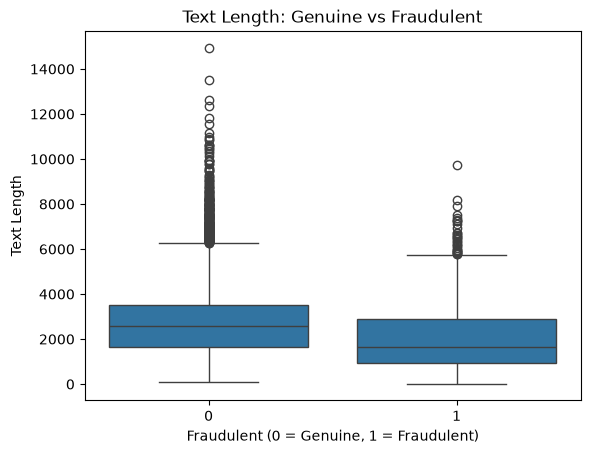

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(
    data=df_copy,
    x='fraudulent',
    y='text_length'
)

plt.title('Text Length: Genuine vs Fraudulent')
plt.xlabel('Fraudulent (0 = Genuine, 1 = Fraudulent)')
plt.ylabel('Text Length')
plt.show()

In [12]:
df_copy["word_count"]=df_copy['text'].apply(lambda x: len(x.split()))
df_copy.groupby('fraudulent')['word_count'].mean()

fraudulent
0    379.491066
1    282.332564
Name: word_count, dtype: float64

In [13]:
# WORD FREQUENCY
from collections import Counter
all_words=' '.join((df_copy['text'])).lower().split()
word_freq=Counter(all_words)
word_freq.most_common(20)# max are stop words


[('and', 359882),
 ('to', 204861),
 ('the', 199617),
 ('of', 153084),
 ('a', 142835),
 ('in', 125471),
 ('with', 90809),
 ('for', 83409),
 ('our', 64283),
 ('is', 63963),
 ('we', 58358),
 ('are', 45480),
 ('you', 45164),
 ('as', 39704),
 ('be', 38293),
 ('on', 37361),
 ('that', 33510),
 ('will', 33170),
 ('or', 32715),
 ('work', 32243)]

In [14]:
genuine_text = ' '.join(
    df_copy[df_copy['fraudulent'] == 0]['text']
).lower().split()

fraud_text = ' '.join(
    df_copy[df_copy['fraudulent'] == 1]['text']
).lower().split()
genuine_freq = Counter(genuine_text)

fraud_freq = Counter(fraud_text)
print("Genuine:", genuine_freq.most_common(20))

print("Fraudulent:", fraud_freq.most_common(20))

Genuine: [('and', 346247), ('to', 197374), ('the', 193178), ('of', 148229), ('a', 138524), ('in', 121248), ('with', 87528), ('for', 80244), ('our', 62905), ('is', 61970), ('we', 56774), ('are', 43746), ('you', 43488), ('as', 38328), ('be', 37053), ('on', 35977), ('that', 32678), ('will', 32367), ('or', 31351), ('work', 30769)]
Fraudulent: [('and', 13635), ('to', 7487), ('the', 6439), ('of', 4855), ('a', 4311), ('in', 4223), ('with', 3281), ('for', 3165), ('is', 1993), ('are', 1734), ('you', 1676), ('we', 1584), ('work', 1474), ('on', 1384), ('our', 1378), ('as', 1376), ('or', 1364), ('be', 1240), ('experience', 1190), ('your', 1146)]


# checking class imbalance

In [15]:
df_copy['fraudulent'].value_counts()

fraudulent
0    17014
1      866
Name: count, dtype: int64

# splitting data into train test split

In [16]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as ply
X=df_copy.drop('fraudulent',axis=1)
y=df_copy['fraudulent']
x_train,x_test,y_train,y_test=train_test_split(X,y,random_state=42,stratify=y,test_size=0.2)






In [17]:
print(x_train.columns.to_list())
print(x_train.dtypes)

['location', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'text', 'text_length', 'word_count']
location                 str
telecommuting          int64
has_company_logo       int64
has_questions          int64
employment_type          str
required_experience      str
required_education       str
industry                 str
function                 str
text                     str
text_length            int64
word_count             int64
dtype: object


# seperating the cat and num cols for column transformer

In [18]:
num_col=['telecommuting','has_company_logo',
         'has_questions','text_length',
         'word_count']
cat_col=list(df_copy.select_dtypes(include='object').columns)
cat_col.remove('text')
text_Col=['text']


C:\Users\itsaa\AppData\Local\Temp\ipykernel_12956\1592235059.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col=list(df_copy.select_dtypes(include='object').columns)


# column transformer

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer



In [20]:
preprocessor=ColumnTransformer(transformers=
                  [('cat',OneHotEncoder(handle_unknown='ignore'),cat_col),
                                             ('text',TfidfVectorizer(max_features=5000),'text'),
                                             ('num_col',StandardScaler(),num_col)]


)
x_train_preprocessed=preprocessor.fit_transform(x_train)
x_test_preprocessed=preprocessor.transform(x_test)

# importing pipeline

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [22]:
model=Pipeline([
    ('preprocessor',preprocessor),
    ('classifier',LogisticRegression(class_weight='balanced',max_iter=1000,random_state=42))
])
model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['location','telecommuting','has_company_logo',...,'text','text_length', 'word_count']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('text', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remai

In [23]:
y_pred=model.predict(x_test)
y_pred[:10]
df_pred=pd.DataFrame({
    'predicted':y_pred,
    'actual':y_test
})
df_pred

,predicted,actual
16995,0,0
9357,0,0
11561,0,0
1105,0,0
1980,0,0
...,...,...
7039,0,0
14472,0,0
14453,0,0
6296,0,0


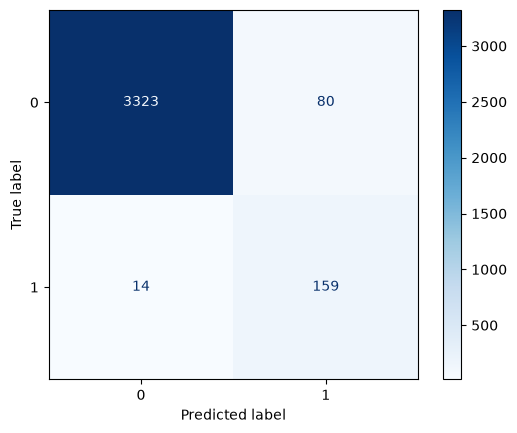

In [24]:
from sklearn.metrics import classification_report,confusion_matrix,ConfusionMatrixDisplay
cme=confusion_matrix(y_test,y_pred)
disp=ConfusionMatrixDisplay(confusion_matrix=cme)
disp.plot(cmap='Blues')


In [25]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      3403
           1       0.67      0.92      0.77       173

    accuracy                           0.97      3576
   macro avg       0.83      0.95      0.88      3576
weighted avg       0.98      0.97      0.98      3576



# fine tuning the model

In [26]:

y_prob=model.predict_proba(x_test)[:,1]
y_prob
for pred in y_prob:
    if pred<0.6:
        print('not fraud',pred)
    else:
        print('fraud',pred)
# predict_proba() calculates the model's estimated probability for each class
# based on X_test (test features), NOT the actual labels in y_test.
#
# [:, 1] selects the probability of class 1 (Fraud).
#
# A low fraud probability (< 0.6) means the model predicts Genuine (0),
# even if the actual label in y_test is Fraud (1).
#
# Comparing predictions with y_test helps us identify mistakes:
# Actual = 1, Predicted = 0 -> False Negative
# Actual = 0, Predicted = 1 -> False Positive


not fraud 0.020183646127704524
not fraud 0.011805546008268959
not fraud 0.08442375909267123
not fraud 0.011367101064981499
not fraud 0.005800097976952686
not fraud 0.005917149592933792
not fraud 0.007534729577713309
not fraud 0.04074651665919976
not fraud 0.014195137399104987
not fraud 0.08278397441378908
not fraud 0.011878204035002986
not fraud 0.0724922570340112
not fraud 0.0002866242845006477
not fraud 0.037338281832118646
not fraud 0.006577287163723371
not fraud 0.30623161160723483
not fraud 0.00023258883540627401
not fraud 0.007181967921069393
not fraud 0.1160539411892716
not fraud 0.07066841999145157
not fraud 0.18238959083151693
not fraud 0.2290072023136956
not fraud 0.009134215834291802
not fraud 0.08541202930522405
not fraud 0.008162561180770652
not fraud 0.04727862494930504
not fraud 0.06469816370041241
not fraud 0.0014733546281221785
not fraud 0.01747678967035012
not fraud 0.570477871782791
not fraud 0.2536045150483574
not fraud 0.02513915741920134
not fraud 0.04166738471372

In [27]:
print(model.classes_)

[0 1]


In [28]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7,0.8]

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)

    print("Threshold:", threshold)
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))
    print("----------------------")

Threshold: 0.3
Precision: 0.4585635359116022
Recall: 0.9595375722543352
F1 Score: 0.6205607476635514
----------------------
Threshold: 0.4
Precision: 0.5759717314487632
Recall: 0.9421965317919075
F1 Score: 0.7149122807017544
----------------------
Threshold: 0.5
Precision: 0.6652719665271967
Recall: 0.9190751445086706
F1 Score: 0.7718446601941747
----------------------
Threshold: 0.6
Precision: 0.7673267326732673
Recall: 0.8959537572254336
F1 Score: 0.8266666666666667
----------------------
Threshold: 0.7
Precision: 0.872093023255814
Recall: 0.8670520231213873
F1 Score: 0.8695652173913043
----------------------
Threshold: 0.8
Precision: 0.9041095890410958
Recall: 0.7630057803468208
F1 Score: 0.8275862068965517
----------------------


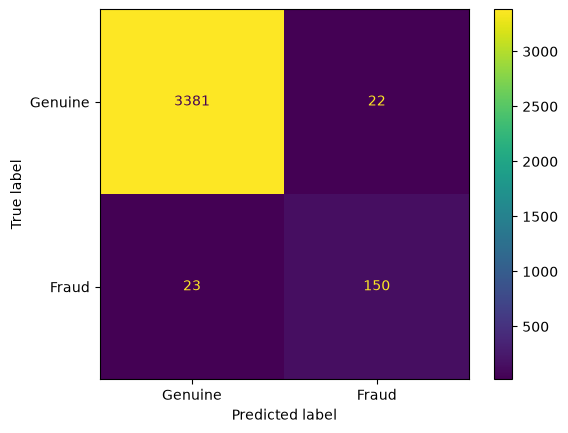

In [29]:
y_pred_final = (y_prob >= 0.7).astype(int)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_final)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Genuine', 'Fraud']
).plot()

plt.show()

In [30]:
from sklearn.svm import LinearSVC
svm_model=Pipeline([('preprocessor',preprocessor),
                    ('classifier',LinearSVC(max_iter=2000,random_state=42,class_weight='balanced'))])
svm_model.fit(x_train,y_train)
y_pred_svm=svm_model.predict(x_test)

In [31]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))
print(confusion_matrix(y_test, y_pred_svm))

Accuracy: 0.9865771812080537
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3403
           1       0.85      0.88      0.86       173

    accuracy                           0.99      3576
   macro avg       0.92      0.94      0.93      3576
weighted avg       0.99      0.99      0.99      3576

[[3375   28]
 [  20  153]]


# Saving the Logistic Regression model
# Selected over Linear SVM because it achieved better
# fraud-class precision and F1-score at threshold 0.7.

In [32]:
import joblib
joblib.dump({
    'pipeline':model,
    'threshold':0.7,
    },'fake_job_post_detector_model.pkl'
)

['fake_job_post_detector_model.pkl']